In [1]:
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from phase_shift import PhaseConfig, PhaseSolver, remove_carrier, subtract_reference
from phase_shift.backend import asnumpy
from phase_shift.utils import wrap


In [12]:
root = Path("/Users/rodionsa/KAUST Dropbox/Sergei Rodionov/Lab_measurements_shared/HoloEML/20261019_wvl_stack_500_700_5")

files = sorted(root.glob("*nm_*.npz"), key=lambda p: int(p.stem.split("_")[-3].removesuffix("nm")))
wavelengths = [int(p.stem.split("_")[-3].removesuffix("nm")) for p in files]
black_file = next(root.glob("*_black_*.npz"))

black_data = np.load(black_file)
black_ref = black_data["black"].mean(0)

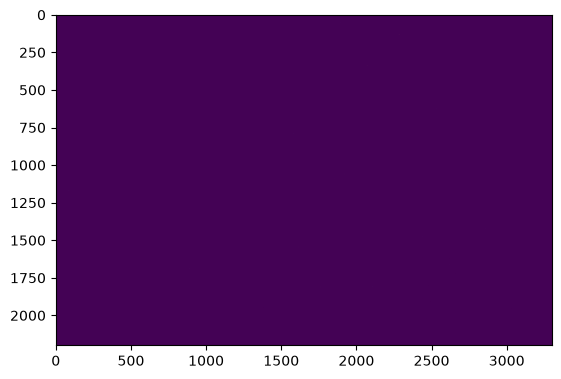

In [ ]:
num = 40

with np.load(files[num]) as d:
    print(d.files)          # names of the arrays stored in the file
    sample_stack = d[d.files[1]][0]
    ref_stack = d[d.files[4]][0]
    

['wavelength', 'stack_sample_pos', 'ref_arm_sample_pos', 'sample_arm_sample_pos', 'stack_ref_pos', 'ref_arm_ref_pos', 'sample_arm_ref_pos', 'n', 'n_back', 'exposure_ms', 'gain', 'move_piezo', 'repeat', 'frames_to_average', 'frames_to_drop', 'piezo_step_fwd', 'piezo_step_bwd', 'reference_x_by', 'reference_y_by']


In [ ]:
N = 15
orders = 3
precision = 'single'

use_alpha = True
gain_mode = "joint"
method = 'vp_aia'
method_kwargs = {"iters": 30, "tol": 1e-4, 
                 "basis": "poly", "basis_kwargs": {"degree": 2}, 
                 "orders": orders, "order_tol": 0.0,
                 "crop": 100}
carrier_degree = 2

config = PhaseConfig(use_alpha=use_alpha, gain_mode=gain_mode, method=method,
                     method_kwargs=method_kwargs, phi_error_simplified=True)
solver = PhaseSolver(config, precision=precision)





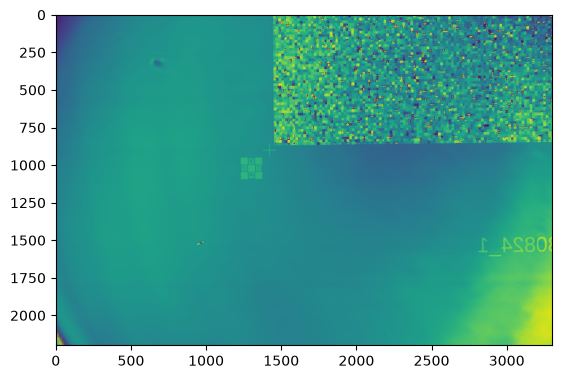

In [ ]:
solver.fit(sample_stack[:N])
result_sample = solver.result
phi_sample = remove_carrier(result_sample.phi, result_sample.b, degree=carrier_degree).phi

solver.fit(ref_stack[:N])
result_ref = solver.result
phi_ref = remove_carrier(result_ref.phi, result_ref.b, degree=carrier_degree).phi

phi = subtract_reference(phi_sample, phi_ref, result_ref.b).phi

Glass Mean: -2.2341573238372803
Glass Std: 1.4911788702011108
Silicon Mean: -3.7029800415039062
Silicon Std: 2.639418125152588


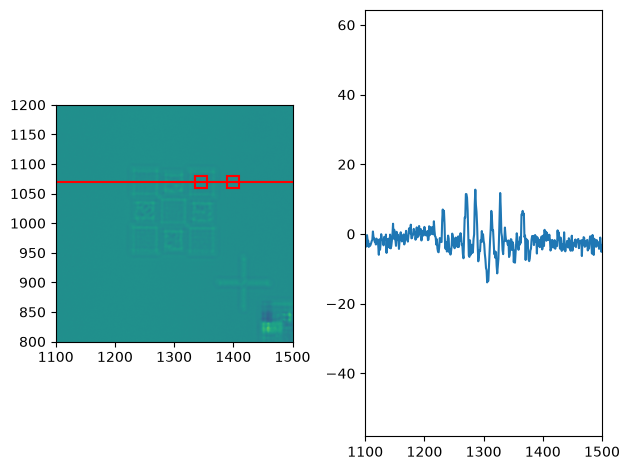

In [151]:
y_line = 1070

ax = plt.subplot(121)
plt.imshow(phi)
plt.ylim([800, 1200])
plt.xlim([1100, 1500])
plt.hlines(y_line, 1100, 1500, color='r')

xc1 = 1345
yc1 = 1070
side1 = 20

xc2 = 1400
yc2 = 1070
side2 = 20

squares = [(xc1 - side1//2, yc1 - side1//2, side1), (xc2 - side2//2, yc2 - side2//2, side2)]   # (x, y, side) in pixels
for x, y, s in squares:
    ax.add_patch(Rectangle((x, y), s, s, fill=False, edgecolor="red", linewidth=1.5))

plt.subplot(122)
plt.plot(phi[y_line]*180/np.pi)
plt.xlim([1100, 1500])

plt.tight_layout()

x, y, s = squares[1]
print(f"Glass Mean: {phi[y:y+s, x:x+s].mean() * 180/np.pi}")   # degrees
print(f"Glass Std: {phi[y:y+s, x:x+s].std() * 180/np.pi}")   # degrees

x, y, s = squares[0]
print(f"Silicon Mean: {phi[y:y+s, x:x+s].mean() * 180/np.pi}")   # degrees
print(f"Silicon Std: {phi[y:y+s, x:x+s].std() * 180/np.pi}")   # degrees

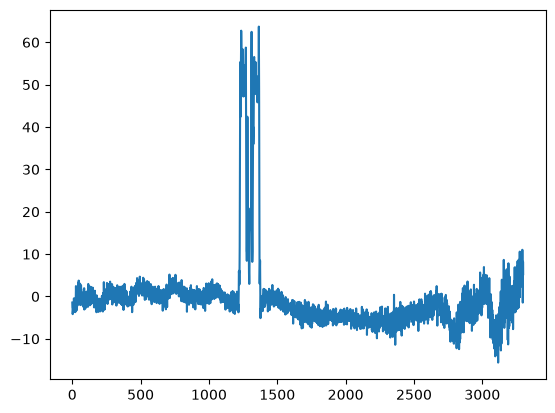

In [108]:
plt.plot(phi[y_line]*180/np.pi)

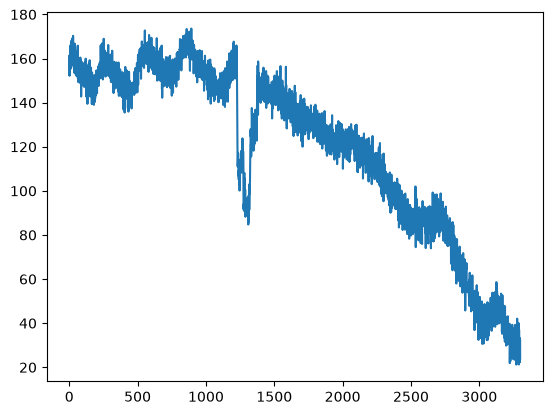

In [33]:
plt.plot((result.b)[1000])